In [32]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

df=pd.read_csv("StudentMarksDataset.csv")

In [33]:
df.sample()

,Std_RollNo,Std_Name,Std_Branch,Std_Course,Std_StudyHours,Std_Marks
148,240562,ANKUR RATHORE,CS,B.Sc 2nd Year,8.3,82.02


In [34]:
df.shape

(200, 6)

In [35]:
df.shape

(200, 6)

In [36]:
df.isnull()

,Std_RollNo,Std_Name,Std_Branch,Std_Course,Std_StudyHours,Std_Marks
0,False,False,False,False,False,False
1,False,False,False,False,False,False
2,False,False,False,False,True,False
3,False,False,False,False,False,False
4,False,False,False,False,False,False
...,...,...,...,...,...,...
195,False,False,False,False,False,False
196,False,False,False,False,False,False
197,False,False,False,False,False,False
198,False,False,False,False,False,False


In [37]:
df.head()

,Std_RollNo,Std_Name,Std_Branch,Std_Course,Std_StudyHours,Std_Marks
0,240415,Tanya Gautam,MC,B.Sc 1st year,6.83,78.50
1,240416,Udit Sagan,MC,B.Sc 1st year,6.56,76.74
2,240417,Kratika Sharma,PM,B.Sc 1st year,NaN,78.68
3,240418,Rakesh Kumar,PM,B.Sc 1st year,5.67,71.82
4,240419,Ritika Katara,PM,B.Sc 1st year,8.67,84.19


In [38]:
df["Std_StudyHours"].isnull()

0      False
1      False
2       True
3      False
4      False
       ...  
195    False
196    False
197    False
198    False
199    False
Name: Std_StudyHours, Length: 200, dtype: bool

In [39]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Std_RollNo      200 non-null    int64  
 1   Std_Name        200 non-null    str    
 2   Std_Branch      197 non-null    str    
 3   Std_Course      200 non-null    str    
 4   Std_StudyHours  195 non-null    float64
 5   Std_Marks       200 non-null    float64
dtypes: float64(2), int64(1), str(3)
memory usage: 9.5 KB


In [40]:
df.describe()

,Std_RollNo,Std_StudyHours,Std_Marks
count,200.000000,195.000000,200.00000
mean,240514.200000,6.995949,77.93375
std,57.515215,1.253060,4.92570
min,240415.000000,5.010000,68.57000
25%,240464.750000,5.775000,73.38500
50%,240514.500000,7.120000,77.71000
75%,240563.250000,8.085000,82.32000
max,240613.000000,8.990000,86.99000


In [41]:
df["Std_StudyHours"] = df["Std_StudyHours"].fillna(
    df["Std_StudyHours"].median()
)


In [42]:
print(df["Std_StudyHours"])

0      6.83
1      6.56
2      7.12
3      5.67
4      8.67
       ... 
195    7.53
196    8.56
197    8.94
198    6.60
199    8.35
Name: Std_StudyHours, Length: 200, dtype: float64


In [43]:
df["Std_StudyHours"].isnull()

0      False
1      False
2      False
3      False
4      False
       ...  
195    False
196    False
197    False
198    False
199    False
Name: Std_StudyHours, Length: 200, dtype: bool

In [44]:
df["Std_StudyHours"].info()

<class 'pandas.Series'>
RangeIndex: 200 entries, 0 to 199
Series name: Std_StudyHours
Non-Null Count  Dtype  
--------------  -----  
200 non-null    float64
dtypes: float64(1)
memory usage: 1.7 KB


In [45]:
df["Std_StudyHours"].skew()

np.float64(-0.06962591001783625)

(array([31., 21., 11., 20., 12., 20., 16., 26., 17., 26.]),
 array([5.01 , 5.408, 5.806, 6.204, 6.602, 7.   , 7.398, 7.796, 8.194,
        8.592, 8.99 ]),
 <BarContainer object of 10 artists>)

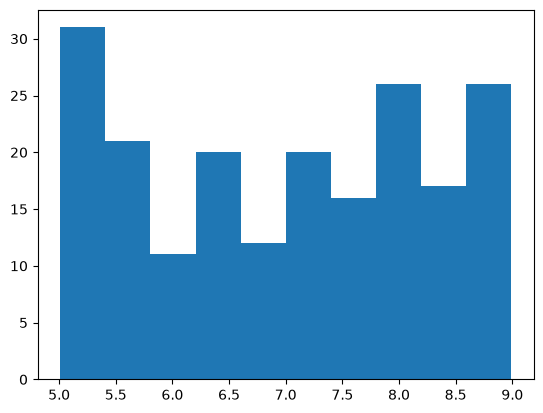

In [46]:
plt.hist(df["Std_StudyHours"])

<Axes: ylabel='Std_StudyHours'>

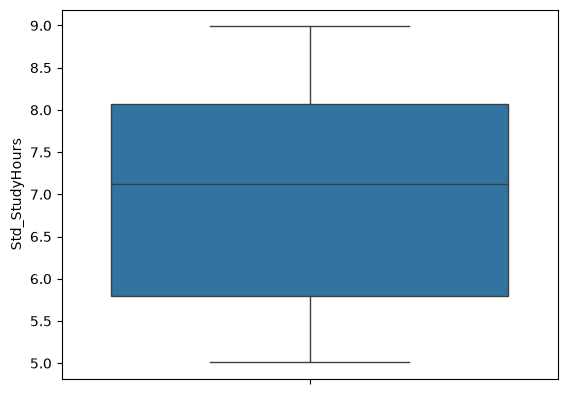

In [47]:
sns.boxplot(df["Std_StudyHours"])

In [48]:
X=df[["Std_StudyHours"]]
y=df["Std_Marks"]

In [59]:
print(X.isnull().sum())
print(y.isnull().sum())

Std_StudyHours    0
dtype: int64
0


In [49]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape)
print(y_train.shape)

(160, 1)
(160,)


In [50]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [51]:
y_pred = model.predict(X_test)

print(y_pred)

[74.33836372 76.14284387 82.3408409  79.98717114 75.47597077 73.16152884
 82.81157485 70.80785908 71.59241566 74.69141418 81.28168951 84.41991585
 71.55318783 70.41558078 85.24370027 73.16152884 73.00461752 82.14470175
 76.57434999 70.33712512 84.53759934 75.39751511 83.007714   81.43860082
 71.82778264 71.98469396 77.43736223 82.85080268 84.77296632 77.24122309
 76.92740045 83.43922012 84.53759934 74.14222457 71.59241566 78.81033626
 83.12539749 70.61171993 81.32091734 70.49403644]


In [52]:
from sklearn.metrics import mean_absolute_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("R2 Score:", r2)

MAE: 0.987019143212984
R2 Score: 0.9424791244450514


In [ ]:
import joblib

joblib.dump(model, "linear_regression_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [54]:
study_hours = pd.DataFrame({
    "Std_StudyHours": [7.5]
})

predicted_marks = model.predict(study_hours)

print("Predicted Marks:", predicted_marks[0])

Predicted Marks: 79.86948765158263
